In [ ]:
## ---------- NOTES ----------
## Sebelumnya mohon maaf pak, saya izin menggunakan VScode dan bukan google collab dikarenakan kendala jaringan di rumah saya yang kurang bagus,
## dan dikhawatirkan akan mengganggu proses coding dan training yang memakan waktu runtime yang cukup lama, takutnya proses trainingnya terhenti 
## di tengah-tengah karena jaringannya putus pada saat proses. Dan disini saya mengalokasikan proses ke GPU saya menggunakan 'cuda'

In [14]:
import torch
import torchvision
import torch.nn as nn
from torchvision import models, transforms, datasets
import numpy as np
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import time
import copy
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score
import os
import matplotlib.pyplot as plt
import random

In [15]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b2 = models.resnet18(weights=weights)

# untuk membekukan semua parameter yang sudah ada
for param in model_b2.parameters():
    param.requires_grad = False

# untuk mengganti classifier head menjadi 10 kelas
num_features = model_b2.fc.in_features
model_b2.fc = nn.Linear(num_features, 10)

# untuk memindahkan model ke GPU jika tersedia
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_b2 = model_b2.to(device)

trainable_params = sum(
    p.numel() for p in model_b2.parameters() if p.requires_grad
)
total_params = sum(p.numel() for p in model_b2.parameters())

print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")
print("Device:", device)

assert trainable_params == 5130, "Jumlah parameter B2 tidak sesuai!"


Trainable parameters: 5,130
Total parameters: 11,181,642
Device: cuda


In [16]:
DATA_DIR = "./data"

trainval_raw = datasets.OxfordIIITPet(
    root=DATA_DIR,
    split="trainval",
    target_types="category",
    download=True
)

test_raw = datasets.OxfordIIITPet(
    root=DATA_DIR,
    split="test",
    target_types="category",
    download=True
)

print("Trainval images:", len(trainval_raw))
print("Official test images:", len(test_raw))
print("Dataset directory:", trainval_raw._base_folder)
print("Example image path:", trainval_raw._images[0])
print("Example labels:", trainval_raw._labels[:10])


Trainval images: 3680
Official test images: 3669
Dataset directory: data\oxford-iiit-pet
Example image path: data\oxford-iiit-pet\images\Abyssinian_100.jpg
Example labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [17]:
annotation_file = (
    Path(trainval_raw._base_folder)
    / "annotations"
    / "list.txt"
)

print("Annotation file exists:", annotation_file.exists())

with annotation_file.open("r", encoding="utf-8") as f:
    for i, line in enumerate(f):
        print(line.rstrip())
        if i >= 14:
            break


Annotation file exists: True
#Image CLASS-ID SPECIES BREED ID
#ID: 1:37 Class ids
#SPECIES: 1:Cat 2:Dog
#BREED ID: 1-25:Cat 1:12:Dog
#All images with 1st letter as captial are cat images
#images with small first letter are dog images
Abyssinian_100 1 1 1
Abyssinian_101 1 1 1
Abyssinian_102 1 1 1
Abyssinian_103 1 1 1
Abyssinian_104 1 1 1
Abyssinian_105 1 1 1
Abyssinian_106 1 1 1
Abyssinian_107 1 1 1
Abyssinian_108 1 1 1


In [18]:
# Lima ras kucing + lima ras anjing
SELECTED_CLASSES = [
    "Abyssinian",
    "Bengal",
    "Birman",
    "Bombay",
    "British_Shorthair",
    "beagle",
    "chihuahua",
    "japanese_chin",
    "pug",
    "samoyed",
]

base_dir = Path(trainval_raw._base_folder)
images_dir = base_dir / "images"
annotation_file = base_dir / "annotations" / "list.txt"

# untuk membaca seluruh anotasi dataset
records = []

with annotation_file.open("r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()

        if not line or line.startswith("#"):
            continue

        parts = line.split()
        image_stem = parts[0]
        class_id = int(parts[1])
        species_id = int(parts[2])

        # Contoh: Abyssinian_100 -> Abyssinian
        breed_name = image_stem.rsplit("_", 1)[0]

        if breed_name in SELECTED_CLASSES:
            image_path = images_dir / f"{image_stem}.jpg"

            if image_path.exists():
                records.append({
                    "image_path": str(image_path),
                    "breed": breed_name,
                    "original_class_id": class_id,
                    "species_id": species_id,
                })

# untuk mapping label jadi 0-9
class_to_idx = {
    name: idx for idx, name in enumerate(SELECTED_CLASSES)
}

for record in records:
    record["label"] = class_to_idx[record["breed"]]

counts = Counter(record["breed"] for record in records)

print("Total selected images:", len(records))
print("\nClass mapping:")

for name, idx in class_to_idx.items():
    print(f"{idx}: {name} -> {counts[name]} images")

print("\nMissing classes:", [
    name for name in SELECTED_CLASSES if counts[name] == 0
])


Total selected images: 1982

Class mapping:
0: Abyssinian -> 198 images
1: Bengal -> 200 images
2: Birman -> 200 images
3: Bombay -> 184 images
4: British_Shorthair -> 200 images
5: beagle -> 200 images
6: chihuahua -> 200 images
7: japanese_chin -> 200 images
8: pug -> 200 images
9: samoyed -> 200 images

Missing classes: []


In [19]:
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)


In [20]:
labels = np.array([record["label"] for record in records])
indices = np.arange(len(records))

# 1. 70% train, 30% temp
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

# 2. bagi temp jadi 15% validation dan 15% test
temp_labels = labels[temp_idx]

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

print(f"Train: {len(train_idx)} ({len(train_idx)/len(records):.1%})")
print(f"Validation: {len(val_idx)} ({len(val_idx)/len(records):.1%})")
print(f"Test: {len(test_idx)} ({len(test_idx)/len(records):.1%})")

assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

print("No overlapping indices between splits.")


Train: 1387 (70.0%)
Validation: 297 (15.0%)
Test: 298 (15.0%)
No overlapping indices between splits.


In [21]:
weights = models.ResNet18_Weights.IMAGENET1K_V1

# Training: augmentasi aktif
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std
    ),
])

# validation dan test: preprocessing deterministik
eval_transforms = weights.transforms()




In [22]:
BATCH_SIZE = 32

class PetBreedDataset(Dataset):
    def __init__(self, records, indices, transform=None):
        self.records = [records[i] for i in indices]
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]

        image = Image.open(record["image_path"]).convert("RGB")
        label = record["label"]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


train_dataset = PetBreedDataset(
    records, train_idx, transform=train_transforms
)
val_dataset = PetBreedDataset(
    records, val_idx, transform=eval_transforms
)
test_dataset = PetBreedDataset(
    records, test_idx, transform=eval_transforms
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

images, batch_labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch labels shape:", batch_labels.shape)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Batch image shape: torch.Size([32, 3, 224, 224])
Batch labels shape: torch.Size([32])
Train batches: 44
Validation batches: 10
Test batches: 10


In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

criterion = nn.CrossEntropyLoss()

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Device: cuda
GPU: NVIDIA GeForce RTX 2050


In [24]:
def train_one_epoch(model, loader, optimizer, criterion, device, frozen_backbone=False):
    model.train()

    # untuk B2: backbone tetap eval agar BatchNorm tidak mengubah running statistics.
    if frozen_backbone:
        model.eval()
        model.fc.train()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        all_labels.extend(labels.detach().cpu().numpy())
        all_predictions.extend(predictions.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_accuracy = accuracy_score(all_labels, all_predictions)

    return epoch_loss, epoch_accuracy





In [25]:
@torch.no_grad()
def evaluate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_accuracy = accuracy_score(all_labels, all_predictions)
    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return epoch_loss, epoch_accuracy, macro_f1





In [26]:
MAX_EPOCHS = 30
PATIENCE = 3
OUTPUT_DIR = "./outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


def fit_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    experiment_name,
    device,
    frozen_backbone=False,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE
):
    model = model.to(device)
    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    best_weights = copy.deepcopy(model.state_dict())
    history = []

    start_time = time.time()

    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, device,
            frozen_backbone=frozen_backbone
        )

        val_loss, val_acc, val_f1 = evaluate_model(
            model, val_loader, criterion, device
        )

        row = {
            "experiment": experiment_name,
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1,
        }
        history.append(row)

        print(
            f"{experiment_name} | Epoch {epoch:02d}/{max_epochs} "
            f"| train_loss={train_loss:.4f} "
            f"| val_loss={val_loss:.4f} "
            f"| val_acc={val_acc:.4f} "
            f"| val_macro_f1={val_f1:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0

            torch.save(
                best_weights,
                os.path.join(OUTPUT_DIR, f"{experiment_name}_best.pth")
            )
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping pada epoch {epoch}.")
            break

    duration_seconds = time.time() - start_time
    model.load_state_dict(best_weights)

    history_df = pd.DataFrame(history)
    history_df.to_csv(
        os.path.join(OUTPUT_DIR, f"{experiment_name}_history.csv"),
        index=False
    )

    print(f"Best epoch: {best_epoch}")
    print(f"Best validation loss: {best_val_loss:.4f}")
    print(f"Training duration: {duration_seconds / 60:.2f} minutes")

    return model, history_df, {
        "experiment": experiment_name,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "duration_seconds": duration_seconds,
        "epochs_completed": len(history),
    }





## B1: ResNet-18 trained from scratch

In [29]:
NUM_CLASSES = 10

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_b1 = models.resnet18(weights=None)
model_b1.fc = nn.Linear(model_b1.fc.in_features, NUM_CLASSES)
model_b1 = model_b1.to(device)

optimizer_b1 = torch.optim.AdamW(
    model_b1.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

trainable_b1 = sum(
    p.numel() for p in model_b1.parameters() if p.requires_grad
)
total_b1 = sum(p.numel() for p in model_b1.parameters())

print("B1 - ResNet18 from scratch")
print(f"Trainable parameters: {trainable_b1:,}")
print(f"Total parameters: {total_b1:,}")
print(f"Device: {device}")
print("Learning rate: 0.001")


B1 - ResNet18 from scratch
Trainable parameters: 11,181,642
Total parameters: 11,181,642
Device: cuda
Learning rate: 0.001


In [108]:
model_b1, history_b1, summary_b1 = fit_model(
    model=model_b1,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b1,
    experiment_name="B1_scratch",
    device=device,
    frozen_backbone=False
)


B1_scratch | Epoch 01/30 | train_loss=2.2890 | val_loss=2.2884 | val_acc=0.2323 | val_macro_f1=0.1712
B1_scratch | Epoch 02/30 | train_loss=1.9358 | val_loss=2.0151 | val_acc=0.3266 | val_macro_f1=0.2741
B1_scratch | Epoch 03/30 | train_loss=1.8104 | val_loss=1.9959 | val_acc=0.3300 | val_macro_f1=0.2672
B1_scratch | Epoch 04/30 | train_loss=1.6916 | val_loss=2.0984 | val_acc=0.3232 | val_macro_f1=0.2874
B1_scratch | Epoch 05/30 | train_loss=1.6475 | val_loss=1.6208 | val_acc=0.4680 | val_macro_f1=0.4555
B1_scratch | Epoch 06/30 | train_loss=1.5648 | val_loss=1.5808 | val_acc=0.4714 | val_macro_f1=0.4641
B1_scratch | Epoch 07/30 | train_loss=1.5145 | val_loss=1.5388 | val_acc=0.4242 | val_macro_f1=0.3954
B1_scratch | Epoch 08/30 | train_loss=1.3787 | val_loss=1.5123 | val_acc=0.5185 | val_macro_f1=0.5120
B1_scratch | Epoch 09/30 | train_loss=1.3966 | val_loss=1.5814 | val_acc=0.5051 | val_macro_f1=0.4791
B1_scratch | Epoch 10/30 | train_loss=1.2790 | val_loss=1.6349 | val_acc=0.4815 | 

## B2: Pretrained ResNet-18, frozen backbone


In [ ]:
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

weights = models.ResNet18_Weights.IMAGENET1K_V1

model_b2 = models.resnet18(weights=weights)

# untuk membekukan seluruh backbone
for param in model_b2.parameters():
    param.requires_grad = False

# untuk mengganti classification head untuk 10 kelas
model_b2.fc = nn.Linear(model_b2.fc.in_features, NUM_CLASSES)

model_b2 = model_b2.to(device)

optimizer_b2 = torch.optim.AdamW(
    model_b2.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

trainable_b2 = sum(
    p.numel() for p in model_b2.parameters()
    if p.requires_grad
)
total_b2 = sum(p.numel() for p in model_b2.parameters())

print("B2 - Pretrained, frozen backbone")
print(f"Trainable parameters: {trainable_b2:,}")
print(f"Total parameters: {total_b2:,}")
print("Learning rate:", 1e-3)

assert trainable_b2 == 5130


B2 - Pretrained, frozen backbone
Trainable parameters: 5,130
Total parameters: 11,181,642
Learning rate: 0.001


In [110]:
model_b2, history_b2, summary_b2 = fit_model(
    model=model_b2,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b2,
    experiment_name="B2_frozen",
    device=device,
    frozen_backbone=True
)


B2_frozen | Epoch 01/30 | train_loss=1.1427 | val_loss=0.4961 | val_acc=0.9024 | val_macro_f1=0.9010
B2_frozen | Epoch 02/30 | train_loss=0.3662 | val_loss=0.2542 | val_acc=0.9630 | val_macro_f1=0.9632
B2_frozen | Epoch 03/30 | train_loss=0.2416 | val_loss=0.2080 | val_acc=0.9630 | val_macro_f1=0.9636
B2_frozen | Epoch 04/30 | train_loss=0.1839 | val_loss=0.1636 | val_acc=0.9697 | val_macro_f1=0.9700
B2_frozen | Epoch 05/30 | train_loss=0.1455 | val_loss=0.1523 | val_acc=0.9697 | val_macro_f1=0.9705
B2_frozen | Epoch 06/30 | train_loss=0.1293 | val_loss=0.1369 | val_acc=0.9764 | val_macro_f1=0.9769
B2_frozen | Epoch 07/30 | train_loss=0.1140 | val_loss=0.1286 | val_acc=0.9764 | val_macro_f1=0.9768
B2_frozen | Epoch 08/30 | train_loss=0.1036 | val_loss=0.1164 | val_acc=0.9697 | val_macro_f1=0.9698
B2_frozen | Epoch 09/30 | train_loss=0.0911 | val_loss=0.1274 | val_acc=0.9697 | val_macro_f1=0.9705
B2_frozen | Epoch 10/30 | train_loss=0.0941 | val_loss=0.1115 | val_acc=0.9764 | val_macro_

## B3: Pretrained ResNet-18, fine-tune layer4 + fc

In [111]:
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

weights = models.ResNet18_Weights.IMAGENET1K_V1
model_b3 = models.resnet18(weights=weights)

for param in model_b3.parameters():
    param.requires_grad = False

model_b3.fc = nn.Linear(model_b3.fc.in_features, NUM_CLASSES)

for param in model_b3.layer4.parameters():
    param.requires_grad = True

model_b3 = model_b3.to(device)

optimizer_b3 = torch.optim.AdamW(
    [
        {
            "params": model_b3.layer4.parameters(),
            "lr": 1e-4
        },
        {
            "params": model_b3.fc.parameters(),
            "lr": 1e-3
        }
    ],
    weight_decay=1e-2
)

trainable_b3 = sum(
    p.numel() for p in model_b3.parameters()
    if p.requires_grad
)
total_b3 = sum(p.numel() for p in model_b3.parameters())

print("Experiment: B3 - Fine-tuning layer4 + fc")
print(f"Trainable parameters: {trainable_b3:,}")
print(f"Total parameters: {total_b3:,}")
print("Layer4 learning rate: 0.0001")
print("FC learning rate: 0.001")

assert trainable_b3 == 8398858


Experiment: B3 - Fine-tuning layer4 + fc
Trainable parameters: 8,398,858
Total parameters: 11,181,642
Layer4 learning rate: 0.0001
FC learning rate: 0.001


In [112]:
model_b3, history_b3, summary_b3 = fit_model(
    model=model_b3,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b3,
    experiment_name="B3_finetune",
    device=device,
    frozen_backbone=False
)

B3_finetune | Epoch 01/30 | train_loss=0.6046 | val_loss=0.0942 | val_acc=0.9764 | val_macro_f1=0.9766
B3_finetune | Epoch 02/30 | train_loss=0.1022 | val_loss=0.0992 | val_acc=0.9663 | val_macro_f1=0.9671
B3_finetune | Epoch 03/30 | train_loss=0.0668 | val_loss=0.0792 | val_acc=0.9731 | val_macro_f1=0.9735
B3_finetune | Epoch 04/30 | train_loss=0.0369 | val_loss=0.0843 | val_acc=0.9764 | val_macro_f1=0.9768
B3_finetune | Epoch 05/30 | train_loss=0.0293 | val_loss=0.0702 | val_acc=0.9764 | val_macro_f1=0.9768
B3_finetune | Epoch 06/30 | train_loss=0.0224 | val_loss=0.0816 | val_acc=0.9764 | val_macro_f1=0.9766
B3_finetune | Epoch 07/30 | train_loss=0.0160 | val_loss=0.0981 | val_acc=0.9663 | val_macro_f1=0.9666
B3_finetune | Epoch 08/30 | train_loss=0.0149 | val_loss=0.1005 | val_acc=0.9562 | val_macro_f1=0.9568
Early stopping pada epoch 8.
Best epoch: 5
Best validation loss: 0.0702
Training duration: 2.74 minutes


## B4: Training transform WITHOUT augmentation

In [ ]:
weights = models.ResNet18_Weights.IMAGENET1K_V1

no_aug_train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=weights.transforms().mean,
        std=weights.transforms().std
    ),
])

# unutk menggunakan split train/val yang sama seperti B1-B3
train_dataset_no_aug = PetBreedDataset(
    records,
    train_idx,
    transform=no_aug_train_transform
)

train_loader_no_aug = DataLoader(
    train_dataset_no_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("B4 no-augmentation training loader ready.")
print("Training images:", len(train_dataset_no_aug))
print("Validation images:", len(val_dataset))


B4 no-augmentation training loader ready.
Training images: 1387
Validation images: 297


In [114]:
# B4-A: Pretrained ResNet18 + augmentation

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_b4_aug = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

for param in model_b4_aug.parameters():
    param.requires_grad = False

model_b4_aug.fc = nn.Linear(
    model_b4_aug.fc.in_features,
    NUM_CLASSES
)
model_b4_aug = model_b4_aug.to(device)

optimizer_b4_aug = torch.optim.AdamW(
    model_b4_aug.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

model_b4_aug, history_b4_aug, summary_b4_aug = fit_model(
    model=model_b4_aug,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b4_aug,
    experiment_name="B4_with_augmentation",
    device=device,
    frozen_backbone=True
)


B4_with_augmentation | Epoch 01/30 | train_loss=1.1427 | val_loss=0.4961 | val_acc=0.9024 | val_macro_f1=0.9010
B4_with_augmentation | Epoch 02/30 | train_loss=0.3662 | val_loss=0.2542 | val_acc=0.9630 | val_macro_f1=0.9632
B4_with_augmentation | Epoch 03/30 | train_loss=0.2416 | val_loss=0.2080 | val_acc=0.9630 | val_macro_f1=0.9636
B4_with_augmentation | Epoch 04/30 | train_loss=0.1839 | val_loss=0.1636 | val_acc=0.9697 | val_macro_f1=0.9700
B4_with_augmentation | Epoch 05/30 | train_loss=0.1455 | val_loss=0.1523 | val_acc=0.9697 | val_macro_f1=0.9705
B4_with_augmentation | Epoch 06/30 | train_loss=0.1293 | val_loss=0.1369 | val_acc=0.9764 | val_macro_f1=0.9769
B4_with_augmentation | Epoch 07/30 | train_loss=0.1140 | val_loss=0.1286 | val_acc=0.9764 | val_macro_f1=0.9768
B4_with_augmentation | Epoch 08/30 | train_loss=0.1036 | val_loss=0.1164 | val_acc=0.9697 | val_macro_f1=0.9698
B4_with_augmentation | Epoch 09/30 | train_loss=0.0911 | val_loss=0.1274 | val_acc=0.9697 | val_macro_f1

In [115]:
# B4-B: Pretrained ResNet18 WITHOUT augmentation

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model_b4_no_aug = models.resnet18(
    weights=models.ResNet18_Weights.IMAGENET1K_V1
)

for param in model_b4_no_aug.parameters():
    param.requires_grad = False

model_b4_no_aug.fc = nn.Linear(
    model_b4_no_aug.fc.in_features,
    NUM_CLASSES
)
model_b4_no_aug = model_b4_no_aug.to(device)

optimizer_b4_no_aug = torch.optim.AdamW(
    model_b4_no_aug.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

model_b4_no_aug, history_b4_no_aug, summary_b4_no_aug = fit_model(
    model=model_b4_no_aug,
    train_loader=train_loader_no_aug,
    val_loader=val_loader,
    optimizer=optimizer_b4_no_aug,
    experiment_name="B4_without_augmentation",
    device=device,
    frozen_backbone=True
)


B4_without_augmentation | Epoch 01/30 | train_loss=1.0446 | val_loss=0.4382 | val_acc=0.9327 | val_macro_f1=0.9312
B4_without_augmentation | Epoch 02/30 | train_loss=0.2818 | val_loss=0.2387 | val_acc=0.9596 | val_macro_f1=0.9607
B4_without_augmentation | Epoch 03/30 | train_loss=0.1694 | val_loss=0.1859 | val_acc=0.9697 | val_macro_f1=0.9703
B4_without_augmentation | Epoch 04/30 | train_loss=0.1275 | val_loss=0.1498 | val_acc=0.9731 | val_macro_f1=0.9731
B4_without_augmentation | Epoch 05/30 | train_loss=0.1004 | val_loss=0.1370 | val_acc=0.9731 | val_macro_f1=0.9731
B4_without_augmentation | Epoch 06/30 | train_loss=0.0838 | val_loss=0.1175 | val_acc=0.9731 | val_macro_f1=0.9731
B4_without_augmentation | Epoch 07/30 | train_loss=0.0708 | val_loss=0.1121 | val_acc=0.9663 | val_macro_f1=0.9666
B4_without_augmentation | Epoch 08/30 | train_loss=0.0619 | val_loss=0.1065 | val_acc=0.9731 | val_macro_f1=0.9732
B4_without_augmentation | Epoch 09/30 | train_loss=0.0552 | val_loss=0.1012 | va

## B5

In [116]:
def train_one_epoch(model, loader, optimizer, criterion, device, frozen_backbone=False):
    model.train()

    if frozen_backbone:
        model.eval()

        if hasattr(model, "fc"):
            model.fc.train()
        elif hasattr(model, "classifier"):
            model.classifier.train()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.detach().cpu().numpy())
        all_predictions.extend(predictions.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_accuracy = accuracy_score(all_labels, all_predictions)

    return epoch_loss, epoch_accuracy



In [117]:
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

weights_b5 = models.MobileNet_V2_Weights.DEFAULT
model_b5 = models.mobilenet_v2(weights=weights_b5)

for param in model_b5.parameters():
    param.requires_grad = False

in_features = model_b5.classifier[1].in_features
model_b5.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

model_b5 = model_b5.to(device)

optimizer_b5 = torch.optim.AdamW(
    model_b5.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

trainable_b5 = sum(
    p.numel() for p in model_b5.parameters()
    if p.requires_grad
)
total_b5 = sum(p.numel() for p in model_b5.parameters())

print("Experiment: B5 - MobileNetV2 pretrained")
print(f"Trainable parameters: {trainable_b5:,}")
print(f"Total parameters: {total_b5:,}")
print("Optimizer: AdamW")
print("Learning rate: 0.001")


Experiment: B5 - MobileNetV2 pretrained
Trainable parameters: 12,810
Total parameters: 2,236,682
Optimizer: AdamW
Learning rate: 0.001


In [118]:
model_b5, history_b5, summary_b5 = fit_model(
    model=model_b5,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_b5,
    experiment_name="B5_MobileNetV2",
    device=device,
    frozen_backbone=True
)


B5_MobileNetV2 | Epoch 01/30 | train_loss=1.4082 | val_loss=0.6938 | val_acc=0.9630 | val_macro_f1=0.9622
B5_MobileNetV2 | Epoch 02/30 | train_loss=0.5103 | val_loss=0.3526 | val_acc=0.9596 | val_macro_f1=0.9596
B5_MobileNetV2 | Epoch 03/30 | train_loss=0.3010 | val_loss=0.2430 | val_acc=0.9663 | val_macro_f1=0.9662
B5_MobileNetV2 | Epoch 04/30 | train_loss=0.2152 | val_loss=0.1930 | val_acc=0.9731 | val_macro_f1=0.9731
B5_MobileNetV2 | Epoch 05/30 | train_loss=0.1781 | val_loss=0.1602 | val_acc=0.9764 | val_macro_f1=0.9765
B5_MobileNetV2 | Epoch 06/30 | train_loss=0.1506 | val_loss=0.1429 | val_acc=0.9731 | val_macro_f1=0.9730
B5_MobileNetV2 | Epoch 07/30 | train_loss=0.1272 | val_loss=0.1307 | val_acc=0.9697 | val_macro_f1=0.9699
B5_MobileNetV2 | Epoch 08/30 | train_loss=0.1137 | val_loss=0.1200 | val_acc=0.9663 | val_macro_f1=0.9665
B5_MobileNetV2 | Epoch 09/30 | train_loss=0.1029 | val_loss=0.1134 | val_acc=0.9663 | val_macro_f1=0.9665
B5_MobileNetV2 | Epoch 10/30 | train_loss=0.09

## Evaluation B1-B5

In [119]:
models_to_test = {
    "B1_scratch": model_b1,
    "B2_frozen": model_b2,
    "B3_finetune": model_b3,
    "B4_without_augmentation": model_b4_no_aug,
    "B5_MobileNetV2": model_b5,
}

test_results = []

for experiment_name, model in models_to_test.items():
    test_loss, test_acc, test_macro_f1 = evaluate_model(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=device
    )

    test_results.append({
        "experiment": experiment_name,
        "test_loss": test_loss,
        "test_accuracy": test_acc,
        "test_macro_f1": test_macro_f1,
    })

    print(
        f"{experiment_name} | "
        f"test_loss={test_loss:.4f} | "
        f"test_acc={test_acc:.4f} | "
        f"test_macro_f1={test_macro_f1:.4f}"
    )

test_results_df = pd.DataFrame(test_results)
test_results_df.to_csv(
    os.path.join(OUTPUT_DIR, "final_test_results.csv"),
    index=False
)

display(test_results_df)


B1_scratch | test_loss=1.3981 | test_acc=0.5705 | test_macro_f1=0.5719
B2_frozen | test_loss=0.0867 | test_acc=0.9732 | test_macro_f1=0.9731
B3_finetune | test_loss=0.0937 | test_acc=0.9765 | test_macro_f1=0.9765
B4_without_augmentation | test_loss=0.0878 | test_acc=0.9765 | test_macro_f1=0.9765
B5_MobileNetV2 | test_loss=0.0879 | test_acc=0.9664 | test_macro_f1=0.9662


,experiment,test_loss,test_accuracy,test_macro_f1
0,B1_scratch,1.398072,0.570470,0.571882
1,B2_frozen,0.086666,0.973154,0.973101
2,B3_finetune,0.093659,0.976510,0.976482
3,B4_without_augmentation,0.087785,0.976510,0.976538
4,B5_MobileNetV2,0.087862,0.966443,0.966193


Misclassified images: 10 / 298


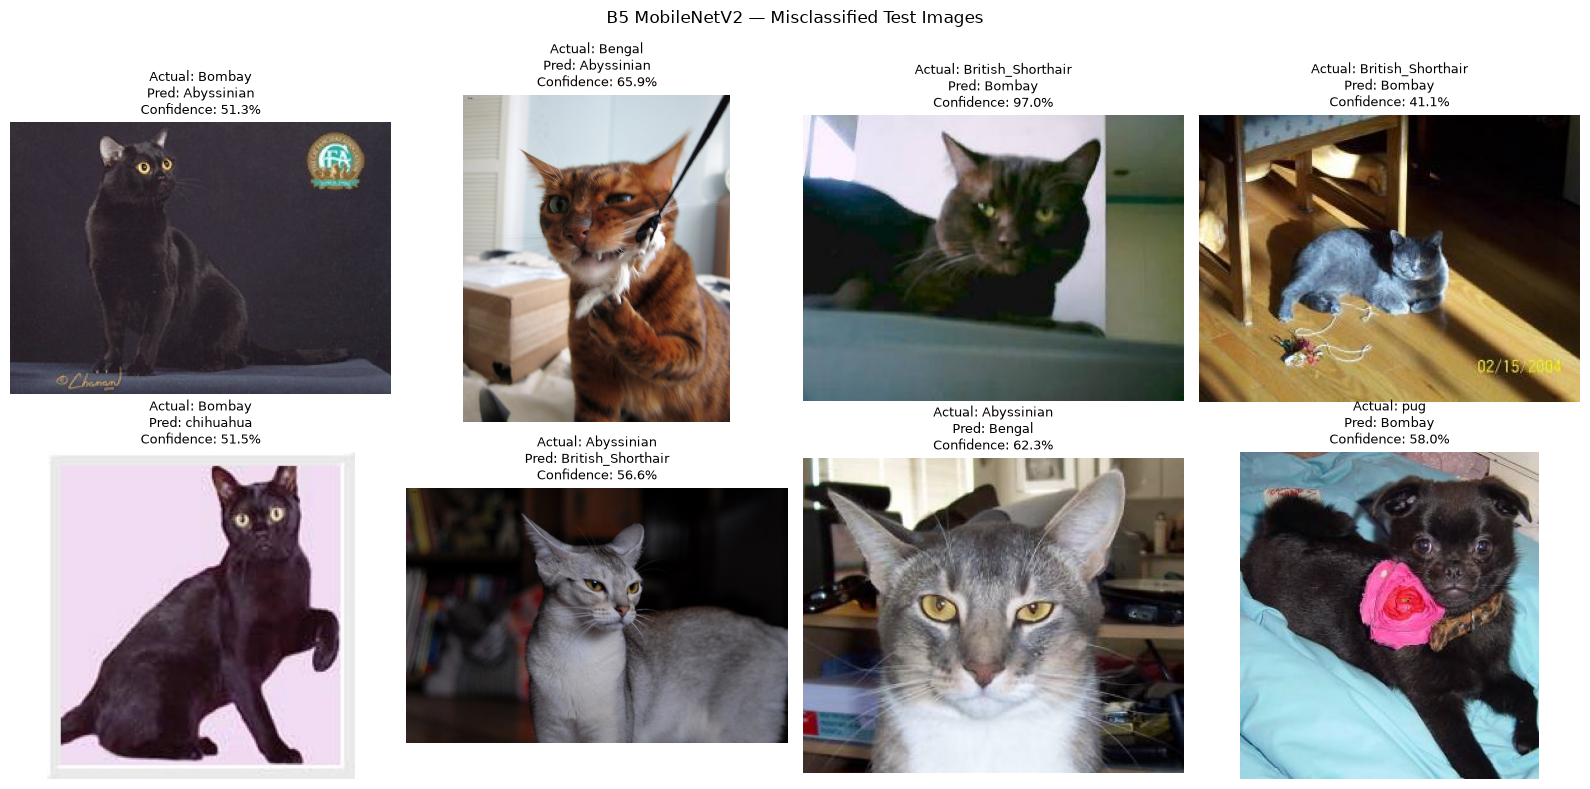

In [120]:

model = model_b5
model.eval()

all_predictions = []
all_confidences = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        confidences, predictions = probabilities.max(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_confidences.extend(confidences.cpu().numpy())
        all_labels.extend(labels.numpy())


idx_to_class = {idx: name for name, idx in class_to_idx.items()}


errors = []
for i, (true_label, pred_label, confidence) in enumerate(
    zip(all_labels, all_predictions, all_confidences)
):
    if true_label != pred_label:
        errors.append({
            "index": i,
            "true_label": int(true_label),
            "pred_label": int(pred_label),
            "confidence": float(confidence),
        })

print(f"Misclassified images: {len(errors)} / {len(all_labels)}")


shown_errors = errors[:8]

if not shown_errors:
    print("No misclassified images found.")
else:
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, error in zip(axes, shown_errors):
        record = test_dataset.records[error["index"]]
        image_path = record["image_path"]

        image = Image.open(image_path).convert("RGB")
        ax.imshow(image)
        ax.set_title(
            f"Actual: {idx_to_class[error['true_label']]}\n"
            f"Pred: {idx_to_class[error['pred_label']]}\n"
            f"Confidence: {error['confidence']:.1%}",
            fontsize=9
        )
        ax.axis("off")

    plt.suptitle("B5 MobileNetV2 — Misclassified Test Images")
    plt.tight_layout()

    os.makedirs(OUTPUT_DIR, exist_ok=True)
    plt.savefig(
        os.path.join(OUTPUT_DIR, "B5_misclassified_test_images.png"),
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


Histories found:
- B1 — ResNet18 from scratch: 17 epochs
- B2 — Frozen ResNet18: 19 epochs
- B3 — Fine-tuned ResNet18: 8 epochs
- B4 — With augmentation: 19 epochs
- B4 — Without augmentation: 23 epochs
- B5 — MobileNetV2: 30 epochs


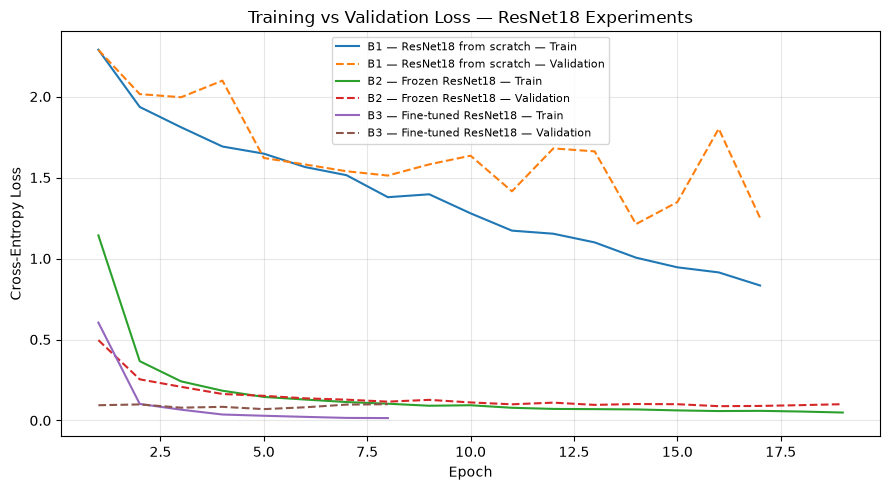

Saved: ./outputs\loss_comparison_B1_B2_B3.png


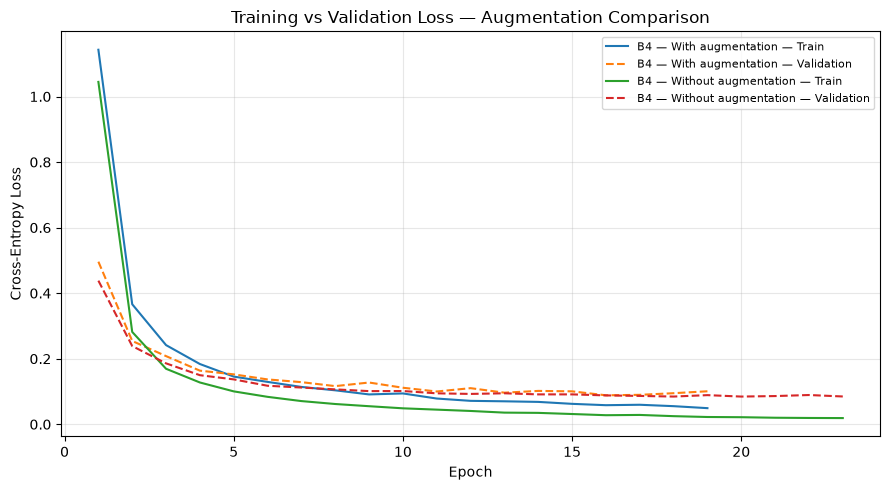

Saved: ./outputs\loss_comparison_augmentation.png


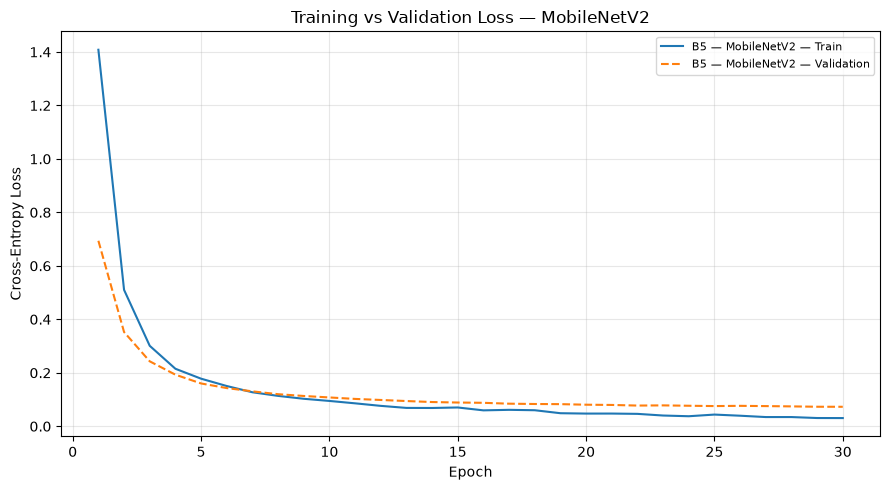

Saved: ./outputs\loss_curve_B5_MobileNetV2.png


In [ ]:
history_candidates = {
    "B1 — ResNet18 from scratch": ["history_b1"],
    "B2 — Frozen ResNet18": ["history_b2"],
    "B3 — Fine-tuned ResNet18": ["history_b3"],
    "B4 — With augmentation": ["history_b4_aug", "history_b4"],
    "B4 — Without augmentation": ["history_b4_no_aug"],
    "B5 — MobileNetV2": ["history_b5"],
}

histories = {}
for experiment, candidates in history_candidates.items():
    for variable_name in candidates:
        if variable_name in globals():
            histories[experiment] = globals()[variable_name]
            break

print("Histories found:")
for name, history in histories.items():
    print(f"- {name}: {len(history)} epochs")

missing = set(history_candidates) - set(histories)
if missing:
    print("\nHistories not found:")
    for name in missing:
        print(f"- {name}")

os.makedirs(OUTPUT_DIR, exist_ok=True)

def plot_loss_curves(experiments, filename, title):
    available = {
        name: histories[name]
        for name in experiments
        if name in histories
    }

    if not available:
        print(f"No history available for: {title}")
        return

    fig, ax = plt.subplots(figsize=(9, 5))

    for name, history in available.items():
        
        ax.plot(
            history["epoch"],
            history["train_loss"],
            linestyle="-",
            label=f"{name} — Train"
        )
        ax.plot(
            history["epoch"],
            history["val_loss"],
            linestyle="--",
            label=f"{name} — Validation"
        )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()

    save_path = os.path.join(OUTPUT_DIR, filename)
    fig.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"Saved: {save_path}")

# 1: memmbandingkan strategi training ResNet18 
plot_loss_curves(
    [
        "B1 — ResNet18 from scratch",
        "B2 — Frozen ResNet18",
        "B3 — Fine-tuned ResNet18",
    ],
    "loss_comparison_B1_B2_B3.png",
    "Training vs Validation Loss — ResNet18 Experiments"
)

# 2: Augmentation comparison
plot_loss_curves(
    [
        "B4 — With augmentation",
        "B4 — Without augmentation",
    ],
    "loss_comparison_augmentation.png",
    "Training vs Validation Loss — Augmentation Comparison"
)

# 3: MobileNetV2
plot_loss_curves(
    ["B5 — MobileNetV2"],
    "loss_curve_B5_MobileNetV2.png",
    "Training vs Validation Loss — MobileNetV2"
)


In [122]:
error_rows = []

for error in errors:
    record = test_dataset.records[error["index"]]

    error_rows.append({
        "image_path": record["image_path"],
        "actual_class": idx_to_class[error["true_label"]],
        "predicted_class": idx_to_class[error["pred_label"]],
        "confidence": round(error["confidence"], 4),
    })

errors_df = pd.DataFrame(error_rows)

display(errors_df.head(8))

errors_df.to_csv(
    os.path.join(OUTPUT_DIR, "B5_misclassification_analysis.csv"),
    index=False
)

print("Saved misclassification table.")


,image_path,actual_class,predicted_class,confidence
0,data\oxford-iiit-pet\images\Bombay_2.jpg,Bombay,Abyssinian,0.5128
1,data\oxford-iiit-pet\images\Bengal_84.jpg,Bengal,Abyssinian,0.6587
2,data\oxford-iiit-pet\images\British_Shorthair_...,British_Shorthair,Bombay,0.9704
3,data\oxford-iiit-pet\images\British_Shorthair_...,British_Shorthair,Bombay,0.4108
4,data\oxford-iiit-pet\images\Bombay_80.jpg,Bombay,chihuahua,0.5153
5,data\oxford-iiit-pet\images\Abyssinian_8.jpg,Abyssinian,British_Shorthair,0.5659
6,data\oxford-iiit-pet\images\Abyssinian_221.jpg,Abyssinian,Bengal,0.6234
7,data\oxford-iiit-pet\images\pug_190.jpg,pug,Bombay,0.5799


Saved misclassification table.


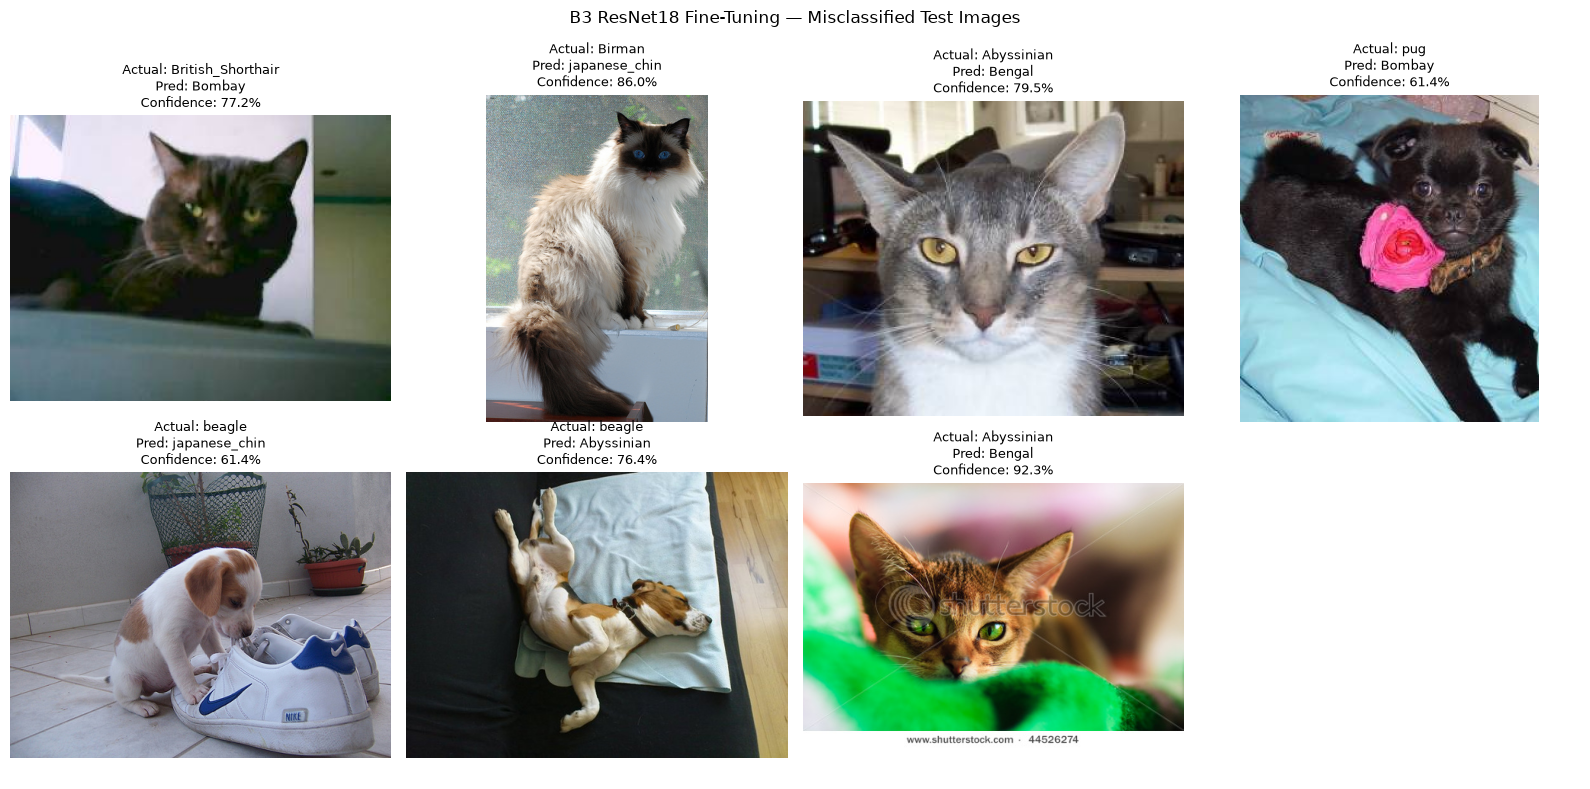

Saved to: C:\Users\ASUS\OneDrive\Documents\2802533163_GSLCDL\src\outputs\B3_misclassified_test_images.png


In [32]:

import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

analysis_df = pd.read_csv("./outputs/B3_misclassification_analysis.csv")
shown = analysis_df.head(7)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for ax, (_, row) in zip(axes, shown.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(
        f"Actual: {row['actual_class']}\n"
        f"Pred: {row['predicted_class']}\n"
        f"Confidence: {row['confidence']:.1%}",
        fontsize=9
    )
    ax.axis("off")

fig.suptitle("B3 ResNet18 Fine-Tuning — Misclassified Test Images")
plt.tight_layout()

output_path = Path("./outputs/B3_misclassified_test_images.png")
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved to:", output_path.resolve())
